# Module 3 Lab — A Complete RAG Pipeline (FAISS + LangChain + LangGraph)

Companion notebook to `1_Retrieval_Augmented_Generation.html`. Builds and runs a full pipeline, end to end, locally:

1. **Chunking** a small document corpus (SS05)
2. **Dense retrieval** via FAISS + sentence-transformers embeddings (SSSS01-03)
3. **Sparse retrieval** via BM25 (SS06)
4. **Hybrid retrieval** — Reciprocal Rank Fusion of both (SS06)
5. **Re-ranking** with a cross-encoder (SS07)
6. **Grounded generation** — two implementations of the same pipeline: a LangChain LCEL chain, and a LangGraph `StateGraph`
7. **Evaluation** — real Recall@k / MRR on a small labeled query set (SS08)
8. **A retrieval failure, demonstrated on purpose** — a question with no answer in the corpus (SS09)

**Models**: `sentence-transformers/all-MiniLM-L6-v2` for embeddings, `cross-encoder/ms-marco-MiniLM-L-6-v2` for re-ranking, `Qwen/Qwen2.5-0.5B-Instruct` for generation — all small enough to run locally, no API key required.

## 0. Setup

This cell installs every library the notebook uses:

- **`torch`, `transformers`** — run the embedding, cross-encoder, and generation models locally.
- **`langchain`, `langchain-huggingface`, `langchain-community`, `langchain-text-splitters`** — chunking utilities, the FAISS vector store wrapper, and the prompt/chain building blocks used in Section 7a.
- **`langgraph`** — the graph-based alternative pipeline built in Section 7b.
- **`faiss-cpu`** — the similarity-search index behind dense retrieval (Section 3).
- **`sentence-transformers`** — supplies both the embedding model (Section 3) and the cross-encoder re-ranker (Section 6).
- **`rank-bm25`** — the sparse, keyword-based retrieval algorithm (Section 4).

Everything below runs on local, open-weight models, so no API key is required.

In [ ]:
# One-time environment setup: everything needed for embeddings, sparse/dense retrieval, re-ranking, and local generation.
# ipywidgets renders the Hugging Face Hub download progress bars (application/vnd.jupyter.widget-view+json) inside the notebook.
%pip install -q torch transformers matplotlib numpy langchain langchain-huggingface langchain-community langchain-text-splitters langgraph faiss-cpu sentence-transformers rank-bm25 ipywidgets

Note: you may need to restart the kernel to use updated packages.


### Picking a device and loading the generation model

This cell does three things:

1. **Device detection** — prefers a CUDA GPU, falls back to Apple Silicon's `mps` backend, then plain CPU, so the notebook runs unmodified on different machines.
2. **Model loading** — downloads `Qwen/Qwen2.5-0.5B-Instruct`, a small instruction-tuned chat model, along with its tokenizer, and moves the model onto the chosen device. `.eval()` disables dropout and other training-only behavior, since we only ever run inference.
3. **`chat()` helper** — wraps a plain string in the model's chat template (so it looks like the one-turn conversation the model was fine-tuned to expect), tokenizes it, generates greedily (`do_sample=False` makes outputs deterministic — useful for a reproducible demo), and decodes *only* the newly generated tokens, discarding the echoed prompt.

In [ ]:
import os, re, time
import numpy as np
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM

# Use the fastest backend available: CUDA > Apple Silicon (MPS) > CPU.
if torch.cuda.is_available():
    DEVICE = torch.device("cuda"); DEVICE_NAME = f"CUDA ({torch.cuda.get_device_name(0)})"
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps"); DEVICE_NAME = "Apple Silicon GPU (MPS)"
else:
    DEVICE = torch.device("cpu"); DEVICE_NAME = "CPU"

print(f"device: {DEVICE_NAME}")

# A small (0.5B-parameter) instruction-tuned model -- fast enough for CPU/MPS, still able to follow a grounding prompt.
GEN_MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
gen_tokenizer = AutoTokenizer.from_pretrained(GEN_MODEL_NAME)
gen_model = AutoModelForCausalLM.from_pretrained(GEN_MODEL_NAME).to(DEVICE)
gen_model.eval()  # inference only -- disables dropout etc.

def chat(prompt_text, max_new_tokens=250):
    """Send a single user turn through the model's chat template and return just the reply text."""
    messages = [{"role": "user", "content": prompt_text}]
    # apply_chat_template formats the message the way the model was fine-tuned to expect
    # (special role/turn tokens), rather than feeding it a bare string.
    prompt = gen_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = gen_tokenizer(prompt, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        # do_sample=False -> greedy decoding, so the same prompt always produces the same answer.
        out = gen_model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=gen_tokenizer.eos_token_id)
    # Slice off the input prompt tokens, keeping only what the model newly generated.
    new_tokens = out[0][inputs["input_ids"].shape[1]:]
    return gen_tokenizer.decode(new_tokens, skip_special_tokens=True).strip()

print("Generation model ready.")

device: Apple Silicon GPU (MPS)
Generation model ready.


## 1. The Corpus

A small synthetic "company knowledge base" spanning four topics: policy, HR, product specs, and support -- small enough to inspect by eye, varied enough that retrieval choices actually matter.

Each entry is a `(text, topic)` pair. We wrap each one in a LangChain `Document`, which pairs `page_content` (the text retrieval and generation actually see) with `metadata` (structured fields like `id` and `topic` that we use for bookkeeping -- e.g. checking *which* document was retrieved during evaluation in Section 8 -- but which are invisible to the embedding model and the LLM).

In [ ]:
from langchain_core.documents import Document

# (text, topic) pairs -- the topic label is only used later for bookkeeping, never seen by the models.
RAW_DOCS = [
    ("The company's return policy allows returns within 30 days of purchase with a valid receipt.", "policy"),
    ("Employees are entitled to 15 days of paid annual leave per calendar year, accruing monthly.", "hr"),
    ("Product model X-450 has a battery capacity of 4500mAh and weighs 180 grams.", "product"),
    ("To reset your password, go to Settings > Security > Reset Password and follow the emailed link.", "support"),
    ("Model X-450 supports fast charging up to 65W and reaches 100% in 35 minutes.", "product"),
    ("Sick leave is separate from annual leave and does not require advance notice.", "hr"),
    ("Refunds are processed within 5-7 business days after the returned item is received.", "policy"),
    ("Support ticket priority levels are P1 (critical, 1hr response), P2 (high, 4hr), P3 (normal, 24hr).", "support"),
    ("Model X-450's screen is 6.5 inches with a resolution of 2400x1080.", "product"),
    ("New employees complete a 90-day probationary period before benefits fully vest.", "hr"),
    ("Items marked 'final sale' cannot be returned or exchanged under any circumstances.", "policy"),
    ("For urgent security incidents, contact the on-call engineer via the #incidents Slack channel.", "support"),
    ("Remote employees receive a one-time $500 home office setup stipend.", "hr"),
    ("Model X-450 is IP68 rated, water resistant up to 1.5 meters for 30 minutes.", "product"),
    ("Price matching is honored within 14 days of purchase if a lower price is found at a competitor.", "policy"),
    ("The API rate limit is 1000 requests per minute per API key, documented at endpoint /v2/limits.", "support"),
]

# Wrap each raw string as a LangChain Document; metadata["id"] lets later steps (and the evaluation
# in Section 8) check *which* source document was retrieved, without that id leaking into the text itself.
documents = [Document(page_content=text, metadata={"id": i, "topic": topic}) for i, (text, topic) in enumerate(RAW_DOCS)]
print(f"{len(documents)} documents loaded across topics: {set(d.metadata['topic'] for d in documents)}")

16 documents loaded across topics: {'support', 'policy', 'product', 'hr'}


## 2. Chunking (SS05)

Real documents are usually far longer than a single embedding model's comfortable input size, so they're split into smaller **chunks** before indexing -- both because embedding models compress a fixed-size vector regardless of input length (a giant chunk gets "averaged out" and loses precision) and because retrieval should return focused, relevant spans, not entire documents.

`RecursiveCharacterTextSplitter` tries to split on the most natural boundary first (paragraph breaks), and only falls back to sentences, then words, then raw characters, if a piece is still too long. Two parameters control it:

- **`chunk_size`** — the target maximum length (in characters) of each chunk.
- **`chunk_overlap`** — how many characters consecutive chunks share, so a sentence that would otherwise be cut in half at a chunk boundary still appears whole in at least one chunk.

Each source document here is already short, so with `chunk_size=120` every document ends up as exactly one chunk -- but the mechanism is the same regardless of document length.

In [ ]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

# chunk_size=120 chars is larger than every document here, so splitting is a no-op in this demo --
# with longer documents, this is where paragraph/sentence/word splitting would kick in.
splitter = RecursiveCharacterTextSplitter(chunk_size=120, chunk_overlap=20)
chunks = splitter.split_documents(documents)
print(f"{len(documents)} documents -> {len(chunks)} chunks (chunk_size=120, overlap=20)")
for c in chunks[:16]:
    print(f"  [{c.metadata['id']}] {c.page_content}")

16 documents -> 16 chunks (chunk_size=120, overlap=20)
  [0] The company's return policy allows returns within 30 days of purchase with a valid receipt.
  [1] Employees are entitled to 15 days of paid annual leave per calendar year, accruing monthly.
  [2] Product model X-450 has a battery capacity of 4500mAh and weighs 180 grams.
  [3] To reset your password, go to Settings > Security > Reset Password and follow the emailed link.
  [4] Model X-450 supports fast charging up to 65W and reaches 100% in 35 minutes.
  [5] Sick leave is separate from annual leave and does not require advance notice.
  [6] Refunds are processed within 5-7 business days after the returned item is received.
  [7] Support ticket priority levels are P1 (critical, 1hr response), P2 (high, 4hr), P3 (normal, 24hr).
  [8] Model X-450's screen is 6.5 inches with a resolution of 2400x1080.
  [9] New employees complete a 90-day probationary period before benefits fully vest.
  [10] Items marked 'final sale' cannot be r

## 3. Dense Retrieval — FAISS (SSSS01-03)

**Dense retrieval** encodes both the corpus and the query into fixed-length vectors ("embeddings") using a neural embedding model, then finds the chunks whose vectors are closest to the query's vector. Because the model captures *meaning* rather than exact wording, it can match a query to a document that shares almost no vocabulary with it -- something keyword search (Section 4) cannot do.

**FAISS** (Facebook AI Similarity Search) is the index that makes that nearest-neighbor search fast: it stores every chunk's embedding and, given a query embedding, quickly returns the closest ones by vector distance rather than comparing against every chunk one by one (a brute-force scan, which is what actually happens at this small scale, but the same API scales to millions of vectors with approximate indexes).

The query below is a deliberate **paraphrase** -- it shares almost no words with the chunk that answers it -- to demonstrate that dense retrieval matches on semantics, not surface tokens.

In [ ]:
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS

# all-MiniLM-L6-v2: a small (384-dim) sentence embedding model, good enough for short factual chunks
# and cheap enough to run on CPU.
embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")
# Embeds every chunk once and builds a FAISS index over the resulting vectors.
vectorstore = FAISS.from_documents(chunks, embeddings)
print(f"FAISS index built: {vectorstore.index.ntotal} vectors, dim={vectorstore.index.d}")
print(vectorstore.index.is_trained)  # True if the index is ready for searching

# A paraphrase query -- no shared keywords with the matching document, dense retrieval should still find it
paraphrase_query = "How much time off do new hires get each year?"
# Embeds the query the same way and returns the k chunks with the closest vectors.
dense_results = vectorstore.similarity_search(paraphrase_query, k=3)
print(f"\nQuery: {paraphrase_query!r}  (note: shares almost no words with the target doc)")
for r in dense_results:
    print(f"  [{r.metadata['id']}] {r.page_content}")

FAISS index built: 16 vectors, dim=384
True

Query: 'How much time off do new hires get each year?'  (note: shares almost no words with the target doc)
  [1] Employees are entitled to 15 days of paid annual leave per calendar year, accruing monthly.
  [9] New employees complete a 90-day probationary period before benefits fully vest.
  [12] Remote employees receive a one-time $500 home office setup stipend.


In [ ]:
# Example of embedding stored in vector DB
vectorstore.embeddings.embed_query(paraphrase_query)  # returns the query vector, useful for debugging or re-ranking

[-0.008814227767288685,
 -0.05592775717377663,
 0.04446784034371376,
 0.021796736866235733,
 0.02782713994383812,
 -0.05425965413451195,
 -0.11568693071603775,
 -0.07955595850944519,
 -0.023658713325858116,
 -0.052340637892484665,
 0.030416378751397133,
 0.06480041891336441,
 -0.049907609820365906,
 -0.041688598692417145,
 -0.0035448402632027864,
 0.0025145767722278833,
 -0.025945864617824554,
 -0.07360678911209106,
 0.0771111398935318,
 -0.10241497308015823,
 0.016772054135799408,
 -0.09946557134389877,
 -0.03699100762605667,
 -0.08059331029653549,
 0.009497327730059624,
 -0.01577010005712509,
 0.006808253936469555,
 0.002483018673956394,
 -0.014374145306646824,
 0.07353229075670242,
 -0.07983393967151642,
 -0.0010670091724023223,
 0.09890846163034439,
 0.05003723129630089,
 0.013948305509984493,
 0.029167233034968376,
 0.03753749281167984,
 0.024125227704644203,
 -0.03896927833557129,
 0.04311741143465042,
 0.027032848447561264,
 0.022736165672540665,
 -0.0006713581969961524,
 -0.003

## 4. Sparse Retrieval — BM25 (SS06)

**Sparse retrieval** scores documents by literal token (word) overlap with the query rather than meaning. **BM25** (Best Matching 25) is the standard algorithm: it's a refinement of TF-IDF that scores each candidate document higher when it contains more of the query's terms, but with two corrections that make it more robust than a naive term count:

- **Term-frequency saturation** — a document matching a word 10 times isn't treated as 10x more relevant than one matching it once; the contribution of repeated terms flattens out.
- **Length normalization** — a long document naturally contains more words, and so has more chances to match by luck; BM25 discounts matches in long documents to compensate.

BM25 excels at exact identifiers, codes, and rare technical terms (like an endpoint path or a product SKU) that an embedding model may blur together with similar-sounding text. The query below is chosen for exactly that reason -- it contains a literal string (`/v2/limits`) that only one chunk contains verbatim.

In [ ]:
from rank_bm25 import BM25Okapi

def tokenize(text):
    # Lowercase + split into alphanumeric tokens -- BM25 works over these tokens, not raw text.
    return re.findall(r"[a-z0-9]+", text.lower())

corpus_tokens = [tokenize(c.page_content) for c in chunks]
bm25 = BM25Okapi(corpus_tokens)  # precomputes term frequencies/IDF over the whole corpus

def bm25_search(query, k=3):
    scores = bm25.get_scores(tokenize(query))  # one BM25 score per chunk
    top_idx = np.argsort(scores)[::-1][:k]     # top-k by score, descending
    return [(chunks[i], scores[i]) for i in top_idx]

# An exact-identifier query -- BM25 should nail this via literal token overlap
identifier_query = "What is the rate limit for endpoint /v2/limits?"
bm25_results = bm25_search(identifier_query)
print(f"Query: {identifier_query!r}")
for doc, score in bm25_results:
    print(f"  score={score:.2f}  [{doc.metadata['id']}] {doc.page_content}")

print("\nSame query through dense retrieval, for comparison:")
for r in vectorstore.similarity_search(identifier_query, k=3):
    print(f"  [{r.metadata['id']}] {r.page_content}")

Query: 'What is the rate limit for endpoint /v2/limits?'
  score=11.94  [15] The API rate limit is 1000 requests per minute per API key, documented at endpoint /v2/limits.
  score=2.85  [11] For urgent security incidents, contact the on-call engineer via the #incidents Slack channel.
  score=2.13  [13] Model X-450 is IP68 rated, water resistant up to 1.5 meters for 30 minutes.

Same query through dense retrieval, for comparison:
  [15] The API rate limit is 1000 requests per minute per API key, documented at endpoint /v2/limits.
  [7] Support ticket priority levels are P1 (critical, 1hr response), P2 (high, 4hr), P3 (normal, 24hr).
  [13] Model X-450 is IP68 rated, water resistant up to 1.5 meters for 30 minutes.


## 5. Hybrid Retrieval — Reciprocal Rank Fusion (SS06)

Dense and sparse retrieval fail in complementary ways: dense retrieval can miss exact identifiers, sparse retrieval can miss paraphrases. **Hybrid retrieval** runs both and combines their results, so a chunk found by *either* method has a chance of surfacing.

The combination method here is **Reciprocal Rank Fusion (RRF)**. Rather than mixing raw scores from the two methods -- which is awkward because BM25 scores and cosine/L2 distances live on completely different, incomparable scales -- RRF looks only at each document's **rank** (its position: 1st, 2nd, 3rd, ...) in each ranked list, and gives it a fusion score of:

```
score(doc) = sum, over every list the doc appears in, of  1 / (k_const + rank)
```

A document ranked highly (small `rank`) contributes a larger score; `k_const` (60 here, the value from the original RRF paper) softens the effect of small rank differences so that rank 1 vs. rank 2 doesn't dominate the fusion. Scores from the two lists are simply added, so a chunk that ranks well in *both* dense and sparse retrieval rises to the top, and a chunk found by only one method still gets partial credit.

In [ ]:
def rrf_fuse(dense_docs, bm25_doc_score_pairs, k_const=60, top_k=3):
    """Reciprocal Rank Fusion: combine two ranked lists by rank position, not raw score."""
    scores = {}
    doc_lookup = {}
    # rank+1 because rank is 0-indexed but RRF's formula expects rank starting at 1.
    for rank, doc in enumerate(dense_docs):
        doc_id = doc.metadata["id"]
        scores[doc_id] = scores.get(doc_id, 0) + 1 / (k_const + rank + 1)
        doc_lookup[doc_id] = doc
    for rank, (doc, _) in enumerate(bm25_doc_score_pairs):
        doc_id = doc.metadata["id"]
        # Same doc_id accumulates score from both lists -- this is the "fusion" step.
        scores[doc_id] = scores.get(doc_id, 0) + 1 / (k_const + rank + 1)
        doc_lookup[doc_id] = doc
    ranked_ids = sorted(scores, key=scores.get, reverse=True)[:top_k]
    return [(doc_lookup[i], scores[i]) for i in ranked_ids]

def hybrid_retrieve(query, k=5, top_k=3):
    # Cast separately with each method (k candidates each), then fuse down to top_k.
    dense_docs = vectorstore.similarity_search(query, k=k)
    bm25_docs = bm25_search(query, k=k)
    return rrf_fuse(dense_docs, bm25_docs, top_k=top_k)

print("Hybrid result for the identifier query:")
for doc, score in hybrid_retrieve(identifier_query):
    print(f"  rrf_score={score:.4f}  [{doc.metadata['id']}] {doc.page_content}")

print("\nHybrid result for the paraphrase query:")
for doc, score in hybrid_retrieve(paraphrase_query):
    print(f"  rrf_score={score:.4f}  [{doc.metadata['id']}] {doc.page_content}")

Hybrid result for the identifier query:
  rrf_score=0.0328  [15] The API rate limit is 1000 requests per minute per API key, documented at endpoint /v2/limits.
  rrf_score=0.0317  [13] Model X-450 is IP68 rated, water resistant up to 1.5 meters for 30 minutes.
  rrf_score=0.0161  [7] Support ticket priority levels are P1 (critical, 1hr response), P2 (high, 4hr), P3 (normal, 24hr).

Hybrid result for the paraphrase query:
  rrf_score=0.0323  [1] Employees are entitled to 15 days of paid annual leave per calendar year, accruing monthly.
  rrf_score=0.0323  [12] Remote employees receive a one-time $500 home office setup stipend.
  rrf_score=0.0323  [9] New employees complete a 90-day probationary period before benefits fully vest.


## 6. Re-ranking — Cross-Encoder (SS07)

Both retrieval methods above are **bi-encoders**: they embed the query and each document *independently*, so similarity is just a distance between two pre-computed vectors. That's fast (embeddings can be precomputed once for the whole corpus), but it limits accuracy -- the model never actually looks at the query and a candidate document *together*.

A **cross-encoder** fixes that: it takes the `(query, document)` pair as a single joint input and outputs one relevance score for that specific pair, letting it model fine-grained interactions between the two texts. This is much more accurate, but far more expensive -- a fresh forward pass is needed for *every* query-document pair, so it doesn't scale to searching an entire corpus. The standard pattern (used here) is to let cheap retrieval (Section 5's hybrid search) cast a wide net of candidates first, then use the expensive cross-encoder only to re-rank that small shortlist.

The scores below are raw, uncalibrated logits (they can be negative) -- only their *relative order* matters, not their absolute magnitude.

In [ ]:
from sentence_transformers import CrossEncoder

# ms-marco-MiniLM-L-6-v2: a small cross-encoder fine-tuned for query-passage relevance ranking.
reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2")

def rerank(query, candidate_docs, top_k=3):
    # Each (query, doc) pair is scored jointly -- this is the expensive step, so candidate_docs
    # should already be a short shortlist (from hybrid_retrieve), not the whole corpus.
    pairs = [[query, doc.page_content] for doc, _ in candidate_docs]
    scores = reranker.predict(pairs)
    order = np.argsort(scores)[::-1][:top_k]  # highest relevance score first
    return [(candidate_docs[i][0], float(scores[i])) for i in order]

wider_candidates = hybrid_retrieve(paraphrase_query, k=8, top_k=6)   # cast a wider net first
reranked = rerank(paraphrase_query, wider_candidates)

print(f"Query: {paraphrase_query!r}")
print("\nBefore re-ranking (hybrid RRF order):")
for doc, score in wider_candidates[:3]:
    print(f"  [{doc.metadata['id']}] {doc.page_content}")
print("\nAfter cross-encoder re-ranking:")
for doc, score in reranked:
    print(f"  relevance={score:.3f}  [{doc.metadata['id']}] {doc.page_content}")

Query: 'How much time off do new hires get each year?'

Before re-ranking (hybrid RRF order):
  [1] Employees are entitled to 15 days of paid annual leave per calendar year, accruing monthly.
  [12] Remote employees receive a one-time $500 home office setup stipend.
  [9] New employees complete a 90-day probationary period before benefits fully vest.

After cross-encoder re-ranking:
  relevance=-0.909  [1] Employees are entitled to 15 days of paid annual leave per calendar year, accruing monthly.
  relevance=-0.964  [9] New employees complete a 90-day probationary period before benefits fully vest.
  relevance=-8.505  [0] The company's return policy allows returns within 30 days of purchase with a valid receipt.


## 7. Grounded Generation — Two Implementations of the Same Pipeline

Retrieval alone only returns source text; **generation** is the step where an LLM turns retrieved chunks plus the question into a natural-language answer. The prompt below explicitly instructs the model to answer *only* from the supplied context and to say so if the answer isn't there -- this grounding instruction is what Section 9 later relies on to prevent hallucination.

The same three-stage pipeline (retrieve -> rerank -> generate) is implemented two ways in this notebook: first as a LangChain **LCEL** chain (below), then as an explicit LangGraph **StateGraph** (Section 7b) -- to show two common ways of structuring the same logic.

### 7a. LangChain LCEL chain

LCEL (LangChain Expression Language) builds a pipeline by piping (`|`) small composable pieces together, similar to Unix pipes. Each piece is a `Runnable`: something that takes an input and produces an output, which becomes the next piece's input.

In [ ]:
from transformers import pipeline as hf_pipeline
from langchain_huggingface import HuggingFacePipeline, ChatHuggingFace
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableLambda

# Wrap the already-loaded generation model as a HF `text-generation` pipeline, then adapt it to
# LangChain's chat interface so it can be used as a Runnable inside the chain below.
lc_pipe = hf_pipeline("text-generation", model=gen_model, tokenizer=gen_tokenizer,
                       max_new_tokens=200, do_sample=False, return_full_text=False)
lc_llm = HuggingFacePipeline(pipeline=lc_pipe)
lc_chat = ChatHuggingFace(llm=lc_llm)

# The grounding instruction: answer only from {context}, and admit when the context doesn't cover it.
RAG_PROMPT = ChatPromptTemplate.from_template(
    "Answer the question using ONLY the context below. If the answer is not in the context, "
    "say \"I don't have that information.\"\n\nContext:\n{context}\n\nQuestion: {question}"
)

def retrieve_and_format(question, top_k=3):
    # retrieve -> rerank -> flatten into a bullet-point context block for the prompt template.
    candidates = hybrid_retrieve(question, k=6, top_k=5)
    top_docs = rerank(question, candidates, top_k=top_k)
    return "\n".join(f"- {doc.page_content}" for doc, _ in top_docs)

# The pipeline as a chain of Runnables: build {context, question} -> fill the prompt template
# -> generate a chat completion -> parse it down to a plain string.
rag_chain = (
    {"context": RunnableLambda(retrieve_and_format), "question": RunnableLambda(lambda x: x)}
    | RAG_PROMPT | lc_chat | StrOutputParser()
)


test_question = "How much time off do new hires get each year?"
print(RAG_PROMPT.format_prompt(context=retrieve_and_format(test_question, top_k=3), question=test_question).to_string())
print("Q:", test_question)
print("A:", rag_chain.invoke(test_question))

Device set to use mps:0


Human: Answer the question using ONLY the context below. If the answer is not in the context, say "I don't have that information."

Context:
- Employees are entitled to 15 days of paid annual leave per calendar year, accruing monthly.
- New employees complete a 90-day probationary period before benefits fully vest.
- Remote employees receive a one-time $500 home office setup stipend.

Question: How much time off do new hires get each year?
Q: How much time off do new hires get each year?
A: New employees receive 15 days of paid annual leave per calendar year.


### 7b. The same pipeline as a LangGraph `StateGraph`

Same three stages, made explicit as graph nodes -- useful once a pipeline grows branches (e.g. re-retrieve on low-confidence, or route to different prompts per topic), which a strictly linear LCEL chain doesn't represent as naturally.

A `StateGraph` is built from:
- A **state schema** (`RAGState`, a `TypedDict`) describing every field that flows through the graph.
- **Nodes** — plain functions that take the current state and return an updated state.
- **Edges** — the fixed order nodes run in (here: `retrieve -> generate -> END`, a straight line, but edges can branch conditionally in more complex graphs).

In [ ]:
from typing import TypedDict, List
from langgraph.graph import StateGraph, END

class RAGState(TypedDict):
    question: str
    retrieved: List[str]
    answer: str

def retrieve_node(state: RAGState) -> RAGState:
    # Same retrieve -> rerank steps as the LCEL chain, just written as a node that mutates state.
    candidates = hybrid_retrieve(state["question"], k=6, top_k=5)
    top_docs = rerank(state["question"], candidates, top_k=3)
    state["retrieved"] = [doc.page_content for doc, _ in top_docs]
    return state

def generate_node(state: RAGState) -> RAGState:
    context = "\n".join(f"- {c}" for c in state["retrieved"])
    prompt = (f"Answer the question using ONLY the context below. If the answer is not in the "
              f"context, say \"I don't have that information.\"\n\nContext:\n{context}\n\n"
              f"Question: {state['question']}")
    state["answer"] = chat(prompt, max_new_tokens=150)
    return state

# Wire the nodes into a straight-line graph: retrieve -> generate -> END.
graph = StateGraph(RAGState)
graph.add_node("retrieve", retrieve_node)
graph.add_node("generate", generate_node)
graph.set_entry_point("retrieve")
graph.add_edge("retrieve", "generate")
graph.add_edge("generate", END)
print(graph.nodes.items())  # optional: show the graph structure in the notebook
rag_graph = graph.compile()

# invoke() runs the graph from entry point to END, threading the state dict through each node.
result = rag_graph.invoke({"question": "What is the battery capacity of the X-450?", "retrieved": [], "answer": ""})
print("Q:", result["question"])
print("Retrieved:", result["retrieved"])
print("A:", result["answer"])

dict_items([('retrieve', StateNodeSpec(runnable=retrieve(tags=None, recurse=True, explode_args=False, func_accepts={}), metadata=None, input_schema=<class '__main__.RAGState'>, retry_policy=None, cache_policy=None, ends=(), defer=False)), ('generate', StateNodeSpec(runnable=generate(tags=None, recurse=True, explode_args=False, func_accepts={}), metadata=None, input_schema=<class '__main__.RAGState'>, retry_policy=None, cache_policy=None, ends=(), defer=False))])
Q: What is the battery capacity of the X-450?
Retrieved: ['Product model X-450 has a battery capacity of 4500mAh and weighs 180 grams.', 'Model X-450 supports fast charging up to 65W and reaches 100% in 35 minutes.', 'Model X-450 is IP68 rated, water resistant up to 1.5 meters for 30 minutes.']
A: The battery capacity of the X-450 is 4500mAh.


## 8. Evaluation — Recall@k and MRR (SS08)

Eyeballing a handful of example queries (Sections 3-6) suggests which retrieval method works better, but doesn't *measure* it. This section runs a small **labeled** query set -- each query paired with the id of the one document that actually answers it -- through all three retrieval strategies (dense, sparse, hybrid) and scores each with two standard information-retrieval metrics:

- **Recall@k** — for what fraction of queries does the gold document appear *anywhere* in the top-k results? This measures whether the right chunk was found at all, ignoring exactly where in the top-k it landed. `Recall@3 = 90%` means the correct document was somewhere in the top 3 results for 9 out of 10 queries.

- **MRR (Mean Reciprocal Rank)** — for each query, take the reciprocal of the gold document's rank (`1/rank`: 1.0 if it's 1st, 0.5 if 2nd, 0.33 if 3rd, 0 if it's outside the top-k entirely), then average that across all queries. Unlike Recall@k, MRR also rewards ranking the right answer *higher*, not just getting it into the list -- a method that always ranks the gold doc 1st scores a perfect 1.0, while one that always ranks it 3rd scores 0.33 even though both achieve 100% Recall@3.

In [ ]:
# (query, gold_document_id) pairs -- the ground truth the metrics below are computed against.
EVAL_QUERIES = [
    ("How long is the return window?", 0),
    ("How much vacation time do I get?", 1),
    ("What's the battery size on the X-450?", 2),
    ("How do I change my password?", 3),
    ("How fast does the X-450 charge?", 4),
    ("Does sick leave need advance notice?", 5),
    ("How long do refunds take to process?", 6),
    ("What's the response time for a critical support ticket?", 7),
    ("What resolution is the X-450 screen?", 8),
    ("How long is the probation period for new hires?", 9),
]

def recall_at_k(retrieve_fn, queries, k=3):
    # Fraction of queries where the gold document id shows up anywhere in the top-k results.
    hits = 0
    for query, gold_id in queries:
        retrieved_ids = [doc.metadata["id"] for doc in retrieve_fn(query, k)]
        hits += gold_id in retrieved_ids
    return hits / len(queries)

def mrr(retrieve_fn, queries, k=5):
    # Average of 1/rank of the gold document (0 if it doesn't appear in the top-k at all).
    total = 0.0
    for query, gold_id in queries:
        retrieved_ids = [doc.metadata["id"] for doc in retrieve_fn(query, k)]
        if gold_id in retrieved_ids:
            total += 1.0 / (retrieved_ids.index(gold_id) + 1)  # +1: rank is 1-indexed
    return total / len(queries)

# Wrap each retrieval strategy behind the same (query, k) -> [Document] interface for a fair comparison.
dense_fn = lambda q, k: vectorstore.similarity_search(q, k=k)
bm25_fn = lambda q, k: [doc for doc, _ in bm25_search(q, k=k)]
hybrid_fn = lambda q, k: [doc for doc, _ in hybrid_retrieve(q, k=8, top_k=k)]

results_table = []
for name, fn in [("Dense (FAISS)", dense_fn), ("Sparse (BM25)", bm25_fn), ("Hybrid (RRF)", hybrid_fn)]:
    r3 = recall_at_k(fn, EVAL_QUERIES, k=3)
    m = mrr(fn, EVAL_QUERIES, k=5)
    results_table.append((name, r3, m))
    print(f"{name:16s}  Recall@3={r3*100:5.1f}%   MRR={m:.3f}")

Dense (FAISS)     Recall@3=100.0%   MRR=1.000
Sparse (BM25)     Recall@3= 90.0%   MRR=0.850


Hybrid (RRF)      Recall@3= 90.0%   MRR=0.925


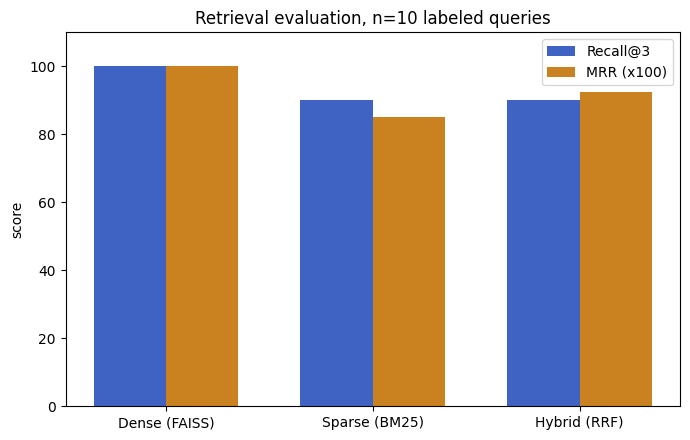

In [ ]:
# Bar chart comparing Recall@3 and MRR across the three retrieval strategies evaluated above.
fig, ax = plt.subplots(figsize=(7, 4.5))
names = [r[0] for r in results_table]
x = np.arange(len(names)); width = 0.35
ax.bar(x - width/2, [r[1]*100 for r in results_table], width, label="Recall@3", color="#3E63C2")
ax.bar(x + width/2, [r[2]*100 for r in results_table], width, label="MRR (x100)", color="#C9821F")  # scaled to sit on the same 0-100 axis as Recall%
ax.set_xticks(x); ax.set_xticklabels(names)
ax.set_ylabel("score"); ax.set_ylim(0, 110)
ax.set_title(f"Retrieval evaluation, n={len(EVAL_QUERIES)} labeled queries")
ax.legend()
plt.tight_layout(); plt.savefig("retrieval_evaluation.png", dpi=150); plt.show()

## 9. A Retrieval Failure, On Purpose (SS09)

Ask something genuinely absent from the corpus. A well-built RAG system should say so -- not confidently invent an answer from the LLM's own parametric knowledge.

This matters because retrieval, by construction, always returns *something*: FAISS and BM25 both return their top-k nearest matches regardless of whether any of them are actually relevant -- there's no built-in "nothing relevant exists" signal. Whether the final answer is trustworthy therefore depends entirely on the generation step honoring the grounding instruction in the prompt ("say I don't have that information") rather than on retrieval somehow detecting the mismatch itself.

In [ ]:
unanswerable_question = "Who is the company's CEO?"
result = rag_graph.invoke({"question": unanswerable_question, "retrieved": [], "answer": ""})
print("Q:", unanswerable_question)
print("Retrieved (nearest matches anyway -- retrieval always returns SOMETHING):")
for r in result["retrieved"]:
    print("  -", r)
print("\nA:", result["answer"])
print("\nThis is exactly SS09's point: retrieval has no 'nothing relevant exists' signal by default --")
print("it always returns its top-k, however irrelevant. Grounding the ANSWER (via the prompt's explicit")
print("\"say I don't have that information\" instruction) is what prevents confident hallucination here,")
print("not the retrieval step itself.")

Q: Who is the company's CEO?
Retrieved (nearest matches anyway -- retrieval always returns SOMETHING):
  - The company's return policy allows returns within 30 days of purchase with a valid receipt.
  - Model X-450's screen is 6.5 inches with a resolution of 2400x1080.
  - Remote employees receive a one-time $500 home office setup stipend.

A: The company's CEO is not explicitly mentioned in the given context. The context only provides information about the product (Model X-450), its features, and the company's return policy. It does not provide any details about the CEO or their role at the company. Therefore, based solely on the provided information, it is impossible to determine who the company's CEO is.

This is exactly SS09's point: retrieval has no 'nothing relevant exists' signal by default --
it always returns its top-k, however irrelevant. Grounding the ANSWER (via the prompt's explicit
"say I don't have that information" instruction) is what prevents confident hallucination h

## Summary

| Stage | Technique | Section |
|---|---|---|
| Chunking | `RecursiveCharacterTextSplitter` | 2 |
| Dense retrieval | FAISS + `all-MiniLM-L6-v2` embeddings | 3 |
| Sparse retrieval | BM25 (`rank_bm25`) | 4 |
| Hybrid retrieval | Reciprocal Rank Fusion | 5 |
| Re-ranking | Cross-encoder (`ms-marco-MiniLM-L-6-v2`) | 6 |
| Generation | LangChain LCEL chain **and** LangGraph `StateGraph` | 7 |
| Evaluation | Recall@3, MRR across 3 retrieval strategies | 8 |
| Failure mode | Unanswerable query, grounded refusal instead of hallucination | 9 |

This directly completes the syllabus lab: *"Build a RAG pipeline using FAISS and LangChain/LangGraph."*